# This is your Python notebook
Start solving by adding a new cell below — write and run code, or jot notes in text cells as you go.

Problem statement:

Porter wants to build a regression model that predicts the estimated delivery time of a food order based on order details, restaurant information, order placement time, and delivery-partner availability.

The prediction helps:
- Customers receive more accurate delivery estimates.
- Delivery partners plan and manage their workload.
- Operations teams optimize delivery allocation and resource planning.
Other applications:

The same approach can be reused in:
- E-commerce platforms to predict package delivery time.
- Grocery delivery applications to estimate order arrival.
- Courier companies to predict shipment arrival times.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Task 1.2 – Import dataset

In [105]:
!gdown https://drive.google.com/uc?id=1kkgBGldeswHBgVKEJiqqG7VZvqZNMc-5 -O Porter.csv

Downloading...
From: https://drive.google.com/uc?id=1kkgBGldeswHBgVKEJiqqG7VZvqZNMc-5
To: /content/Porter.csv
100% 15.7M/15.7M [00:00<00:00, 83.0MB/s]


In [106]:
df = pd.read_csv("Porter.csv")

Task 1.3 – Inspect data structure

In [107]:
df.head()

,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_store_to_consumer_driving_duration
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,861.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,690.0
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,289.0
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,795.0
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,205.0


In [108]:
df.shape

(175777, 14)

In [63]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     175777 non-null  float64
 1   created_at                                    175777 non-null  object 
 2   actual_delivery_time                          175777 non-null  object 
 3   store_primary_category                        175777 non-null  int64  
 4   order_protocol                                175777 non-null  float64
 5   total_items                                   175777 non-null  int64  
 6   subtotal                                      175777 non-null  int64  
 7   num_distinct_items                            175777 non-null  int64  
 8   min_item_price                                175777 non-null  int64  
 9   max_item_price                                17

### Task 1.4 – Three Pandas Datetime Functions / Accessors

1. **pd.to_datetime()** – Converts string or other supported values into Pandas datetime objects.

2. **.dt.hour** – Extracts the hour component (0–23) from a datetime column.

3. **.dt.dayofweek** – Extracts the weekday, where Monday = 0 and Sunday = 6.

### Task 1.5 – Difference Between datetime, timedelta and Period

1. **datetime** – Represents a specific point in time, including date and time. Example: `2026-11-07 10:30:00`.

2. **timedelta** – Represents the duration or difference between two datetime values. Example: `45 minutes` (time taken for a Porter delivery).

3. **Period** – Represents a fixed calendar span such as a month, quarter or year. Example: `March 2024`.


Task 2.1: Convert `created_at` and `actual_delivery_time` from object type to proper datetime type.

In [109]:
df["created_at"] = pd.to_datetime(df['created_at'])
df["actual_delivery_time"] = pd.to_datetime(df['actual_delivery_time'])


Task 2.2: Create the target column by finding the time taken for each delivery, then convert it into a single numeric value in minutes.

In [110]:
df["actual_delivery_duration"] =  df["actual_delivery_time"] -df["created_at"]

In [111]:
df["actual_delivery_duration"] = (
    df["actual_delivery_time"] - df["created_at"]
).dt.total_seconds() / 60

In [112]:
df["actual_delivery_duration"].describe()

,actual_delivery_duration
count,175777.000000
mean,46.203013
std,9.327424
min,32.000000
25%,39.000000
50%,45.000000
75%,52.000000
max,110.000000


In [113]:
df['order_hour'] = df['created_at'].dt.hour

df['order_day'] = df['created_at'].dt.dayofweek

In [114]:
df = df.drop(columns =['created_at','actual_delivery_time'])

In [115]:
df.isna().sum()

,0
market_id,0
store_primary_category,0
order_protocol,0
total_items,0
subtotal,0
num_distinct_items,0
min_item_price,0
max_item_price,0
total_onshift_dashers,0
total_busy_dashers,0


There are no null values present

In [116]:
df['store_primary_category'] = (
    df['store_primary_category'].astype(str)
)

In [118]:
df = pd.get_dummies(
    df,
    columns=['store_primary_category'],
    dtype=int
)

In [119]:
print("Dataset shape:", df.shape)

df.filter(
    like='store_primary_category_'
).head()

Dataset shape: (175777, 87)


,store_primary_category_0,store_primary_category_1,store_primary_category_10,store_primary_category_11,store_primary_category_12,store_primary_category_13,store_primary_category_14,store_primary_category_15,store_primary_category_16,store_primary_category_17,...,store_primary_category_66,store_primary_category_67,store_primary_category_68,store_primary_category_69,store_primary_category_7,store_primary_category_70,store_primary_category_71,store_primary_category_72,store_primary_category_8,store_primary_category_9
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [73]:
print(df.filter(
    like='store_primary_category_'
).shape)

print(df.columns.tolist())

(175777, 73)
['market_id', 'order_protocol', 'total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'estimated_store_to_consumer_driving_duration', 'actual_delivery_duration', 'order_hour', 'order_day', 'store_primary_category_0', 'store_primary_category_1', 'store_primary_category_10', 'store_primary_category_11', 'store_primary_category_12', 'store_primary_category_13', 'store_primary_category_14', 'store_primary_category_15', 'store_primary_category_16', 'store_primary_category_17', 'store_primary_category_18', 'store_primary_category_19', 'store_primary_category_2', 'store_primary_category_20', 'store_primary_category_21', 'store_primary_category_22', 'store_primary_category_23', 'store_primary_category_24', 'store_primary_category_25', 'store_primary_category_26', 'store_primary_category_27', 'store_primary_category_28', 'store_primary_category_29', 'store_primary_category_3', 

In [120]:
df['actual_delivery_duration'].describe()

,actual_delivery_duration
count,175777.000000
mean,46.203013
std,9.327424
min,32.000000
25%,39.000000
50%,45.000000
75%,52.000000
max,110.000000


Task 3.1: Visualize relationships between the target and key features — for example a correlation heatmap and scatterplots of `time_taken_mins` against `subtotal`, and `total_items` against `subtotal`.

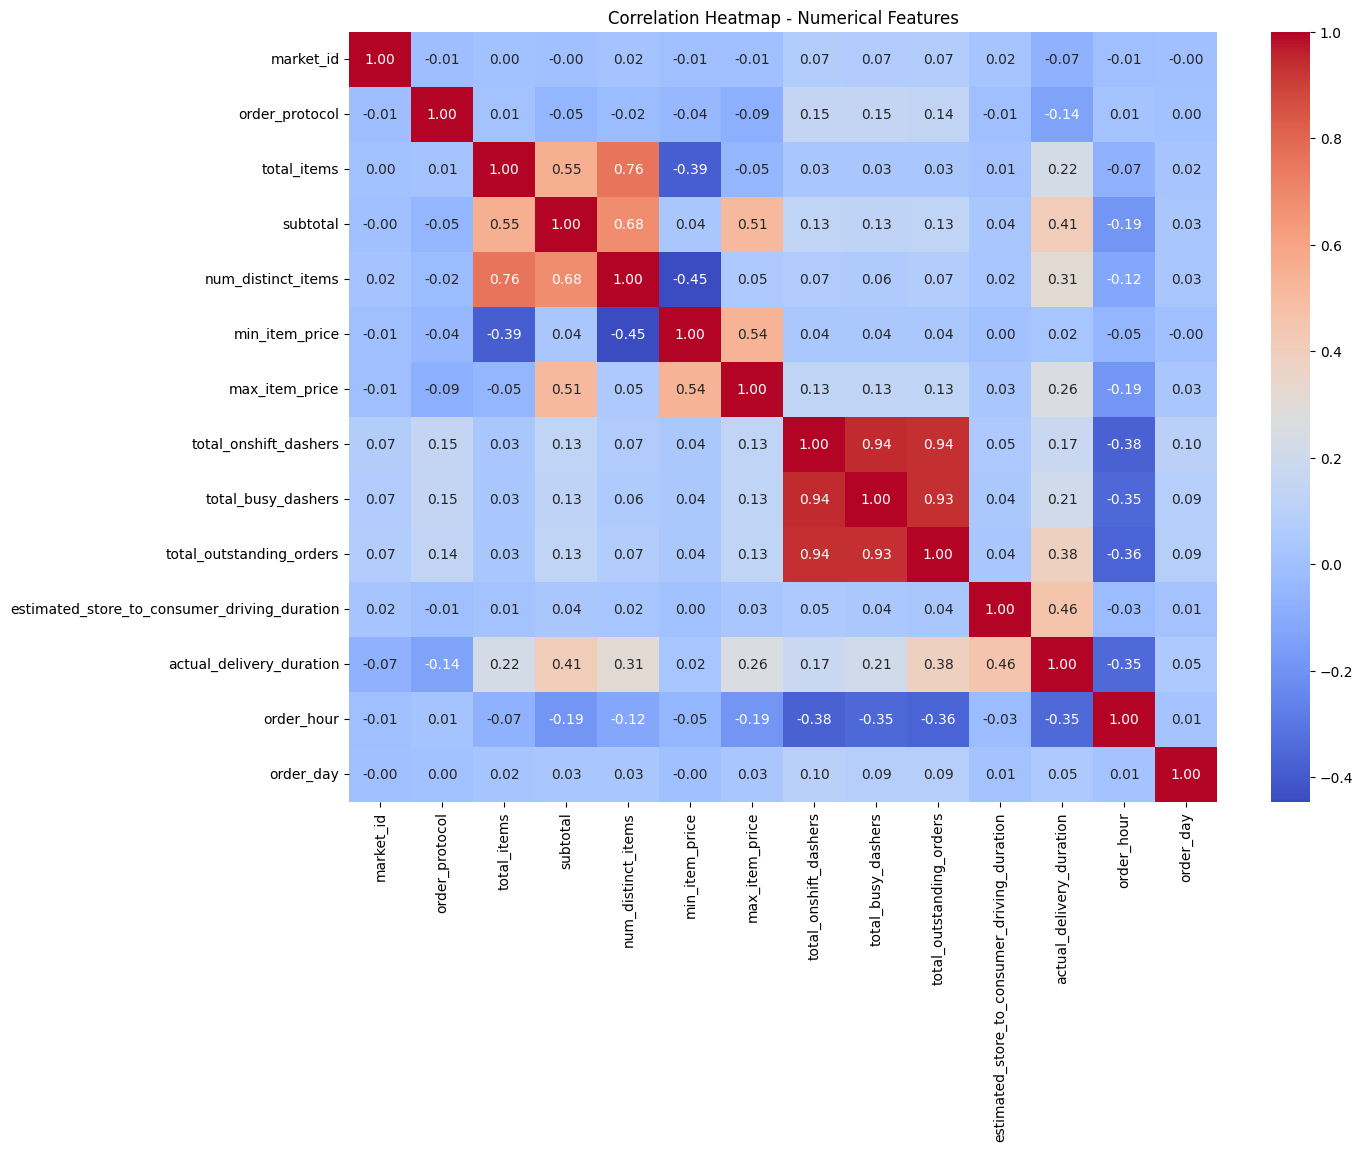

In [121]:
# Exclude One-Hot encoded columns
numeric_cols = df.select_dtypes(include='number').columns

numeric_cols = [
    col for col in numeric_cols
    if not col.startswith('store_primary_category_')
]

plt.figure(figsize=(14, 10))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap - Numerical Features')
plt.show()

### Task 3.1 – Correlation Heatmap: Key Observations

**1. Features positively correlated with delivery duration:**

- `estimated_store_to_consumer_driving_duration` has the highest positive correlation (0.46), indicating that longer estimated driving durations are associated with longer delivery times.
- `subtotal` has a positive correlation of 0.41, suggesting that higher-value orders tend to be associated with longer delivery durations.
- `total_outstanding_orders` has a correlation of 0.38, indicating that higher pending order volumes may be associated with increased delivery times.
- `num_distinct_items` has a correlation of 0.31, showing a moderate positive relationship with delivery duration.

**2. Features negatively correlated with delivery duration:**

- `order_hour` has a negative correlation of -0.35, suggesting that delivery duration varies depending on the hour at which an order is placed.
- `order_protocol` has a weak negative correlation of -0.14.

**3. Multicollinearity observations:**

- `total_onshift_dashers` and `total_busy_dashers` have a high correlation of 0.94.
- `total_onshift_dashers` and `total_outstanding_orders` have a correlation of 0.94.
- `total_busy_dashers` and `total_outstanding_orders` have a correlation of 0.93.
- `total_items` and `num_distinct_items` have a correlation of 0.76.

These relationships indicate potential multicollinearity among some input features.

**4. Key conclusion:**

Estimated driving duration, subtotal and outstanding orders show relatively stronger linear relationships with delivery duration. However, correlation does not imply causation. Features with low linear correlation should not be discarded without further investigation, as they may still contribute to model predictions through nonlinear relationships.

1. Scatterplot – Delivery time vs Subtotal

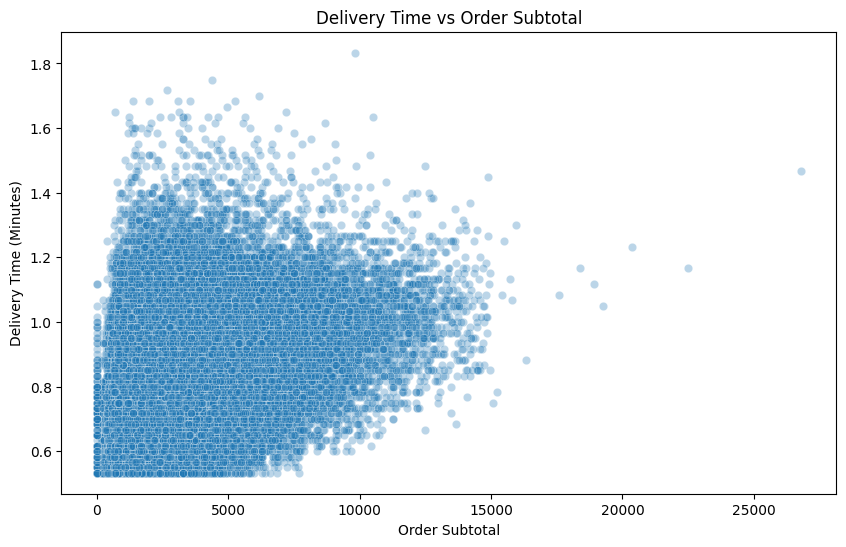

In [75]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='subtotal',
    y='actual_delivery_duration',
    alpha=0.3
)

plt.title('Delivery Time vs Order Subtotal')
plt.xlabel('Order Subtotal')
plt.ylabel('Delivery Time (Minutes)')
plt.show()

The scatterplot shows considerable variation in delivery time across different order subtotals, with no clear linear relationship. This indicates that order value alone may not be a reliable predictor of delivery duration.

Scatterplot — Total Items vs Order Subtotal

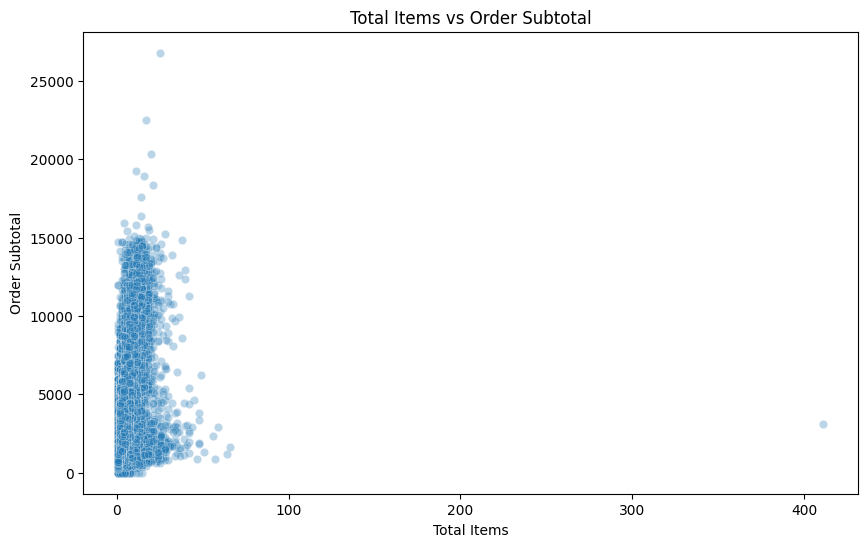

In [76]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='total_items',
    y='subtotal',
    alpha=0.3
)

plt.title('Total Items vs Order Subtotal')
plt.xlabel('Total Items')
plt.ylabel('Order Subtotal')
plt.show()

The scatterplot indicates a general positive relationship between the number of items and order subtotal. However, considerable variation in subtotal exists for similar item counts, possibly due to differences in item prices. An extreme observation with approximately 410 items is also visible and requires further investigation during outlier treatment.

**Task 3.2: Why is it important to check for outliers before training a model?**

Outliers are extreme values that differ significantly from the majority of observations. In the Porter dataset, unusual values such as orders with approximately 410 items may influence the model during training. They can distort statistical measures, affect feature relationships, and increase prediction errors, particularly in models sensitive to extreme values. Identifying and investigating outliers before training helps improve model reliability and prediction accuracy. However, genuine observations should not be removed without proper justification.

**Task 3.3: Name three methods that can be used to detect or remove outliers.**

1. **IQR (Interquartile Range) Method:** Identifies outliers using the lower and upper bounds calculated from the first and third quartiles.

2. **Z-Score Method:** Identifies values that are significantly far from the mean, typically beyond ±3 standard deviations.

3. **Capping (Winsorization):** Handles outliers by replacing extreme values with specified upper and lower percentile limits instead of removing the observations.

**Task 3.4: Apply an outlier detection method to the data, print how many rows were flagged, and remove those rows.**

**Step 1: Select numerical columns**
We should exclude categorical columns such as market_id, order_protocol, order_hour, order_day, and the one-hot encoded category columns.

In [122]:
numeric_cols = [
    'total_items',
    'subtotal',
    'num_distinct_items',
    'min_item_price',
    'max_item_price',
    'total_onshift_dashers',
    'total_busy_dashers',
    'total_outstanding_orders',
    'estimated_store_to_consumer_driving_duration',
    'actual_delivery_duration'
]

In [123]:
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numeric_cols] < lower_bound) |
    (df[numeric_cols] > upper_bound)
).any(axis=1)

# Count rows flagged as outliers
outlier_count = outlier_mask.sum()

print("Number of rows flagged as outliers:", outlier_count)

# Remove outlier rows
df = df.loc[~outlier_mask].copy()

print("Shape after removing outliers:", df.shape)

Number of rows flagged as outliers: 26520
Shape after removing outliers: (149257, 87)


Using the IQR method, 26,520 rows (approximately 15.09% of the original dataset) were identified as outliers and removed. The resulting dataset contains 149,257 rows and 87 columns. This helps reduce the influence of extreme values on subsequent model training.

**Task 3.5: Re-plot the same scatterplot from Task 3.1 after removing outliers, and compare it to the original to confirm the cleaning helped.**

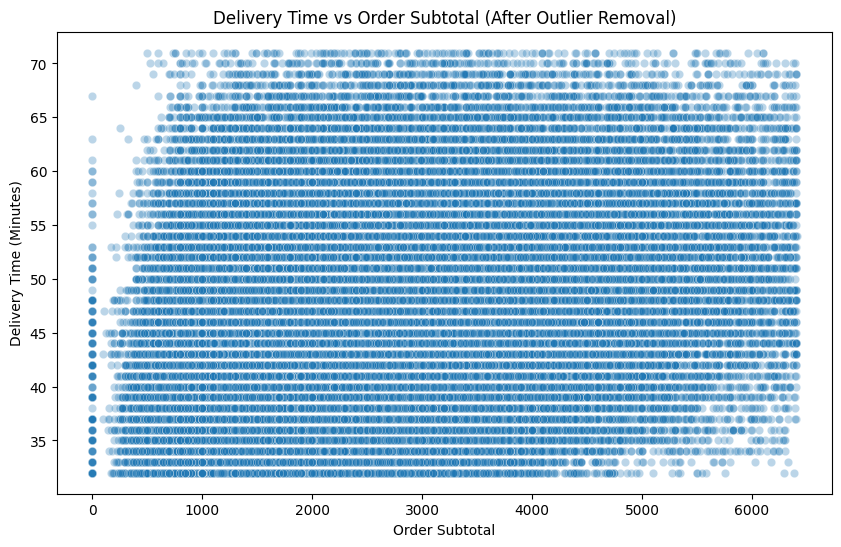

In [124]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='subtotal',
    y='actual_delivery_duration',
    alpha=0.3
)

plt.title('Delivery Time vs Order Subtotal (After Outlier Removal)')
plt.xlabel('Order Subtotal')
plt.ylabel('Delivery Time (Minutes)')
plt.show()

After outlier removal, the scatterplot shows a reduced range of values for both order subtotal and delivery duration. The distribution is more compact, making the main data pattern easier to observe. However, no strong linear relationship between order subtotal and delivery time is evident.

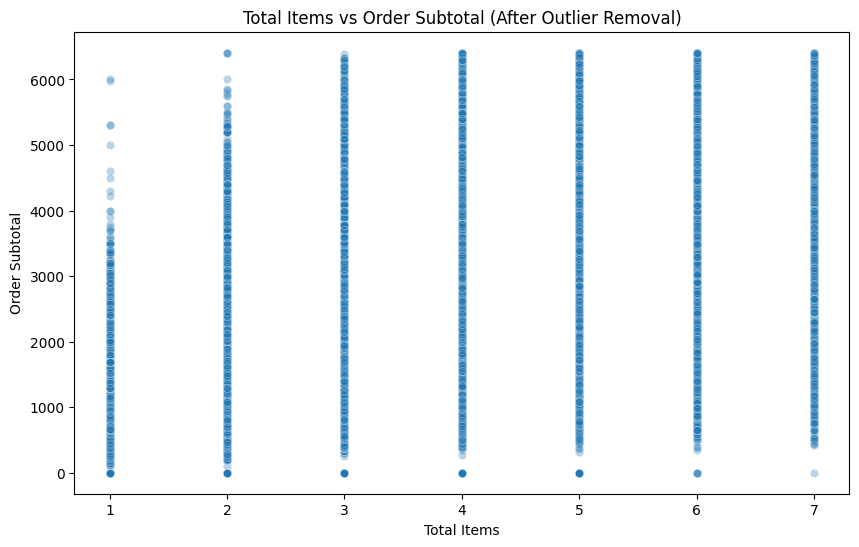

In [128]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='total_items',
    y='subtotal',
    alpha=0.3
)

plt.title('Total Items vs Order Subtotal (After Outlier Removal)')
plt.xlabel('Total Items')
plt.ylabel('Order Subtotal')
plt.show()

After outlier removal, the number of items and order subtotal are within a narrower range. The scatterplot shows a general positive relationship between the two variables, although considerable variation in subtotal remains for each item count. Removing outliers has improved the visualization by reducing the influence of extreme values.

**Task 3.5 – Overall conclusion**
Both scatterplots now show a more compact distribution after outlier removal. The extreme observations have been reduced, making the main data patterns easier to interpret. However, outlier removal has not fundamentally changed the relationships between the variables.

**Task 3.6: Visualize order volume by day of week and hour of day, and check whether time of day affects delivery time.**

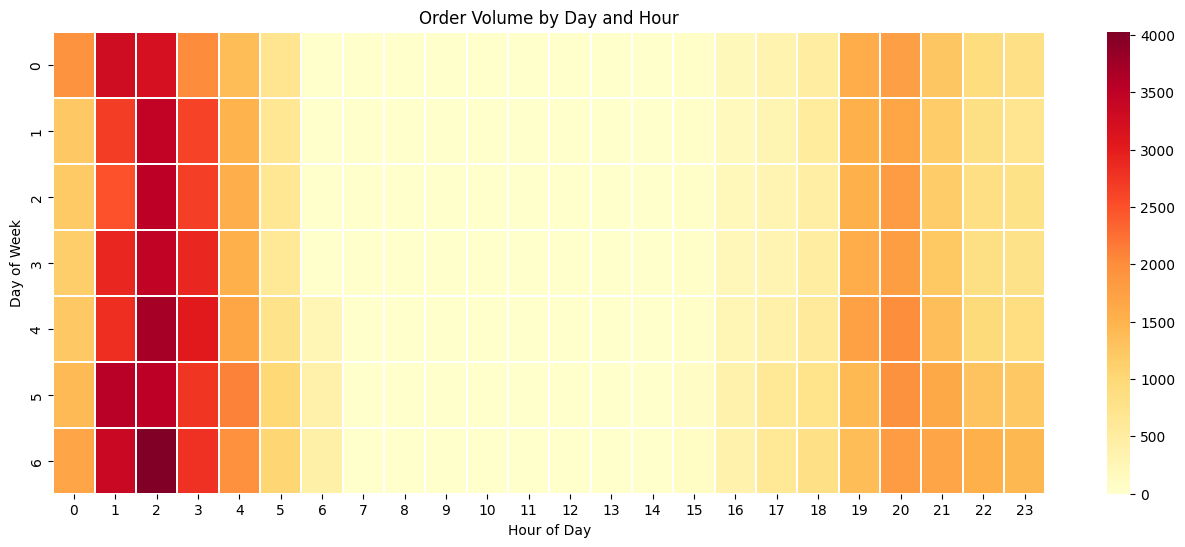

In [131]:
order_volume = df.pivot_table(
    index='order_day',
    columns='order_hour',
    values='total_items',
    aggfunc='count',
    fill_value=0
)

# Include all 24 hours
order_volume = order_volume.reindex(
    columns=range(24),
    fill_value=0
)

plt.figure(figsize=(16, 6))

sns.heatmap(
    order_volume,
    cmap='YlOrRd',
    linewidths=0.3
)

plt.title('Order Volume by Day and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.show()

In [130]:
print(df['order_hour'].value_counts().sort_index())

order_hour
0      9786
1     21101
2     24903
3     18829
4     11734
5      5444
6      1090
7         9
8         2
14       36
15      468
16     1825
17     2885
18     4138
19    10770
20    12830
21     9497
22     7261
23     6649
Name: count, dtype: int64


The heatmap shows that order volume is highest during the early morning hours, particularly between 1 AM and 2 AM, across most days of the week. A secondary increase in order activity is observed during the evening hours, especially between 7 PM and 8 PM. Order volume is considerably lower during the morning and afternoon periods, with some hours having no recorded orders. These patterns indicate that order demand varies significantly throughout the day.

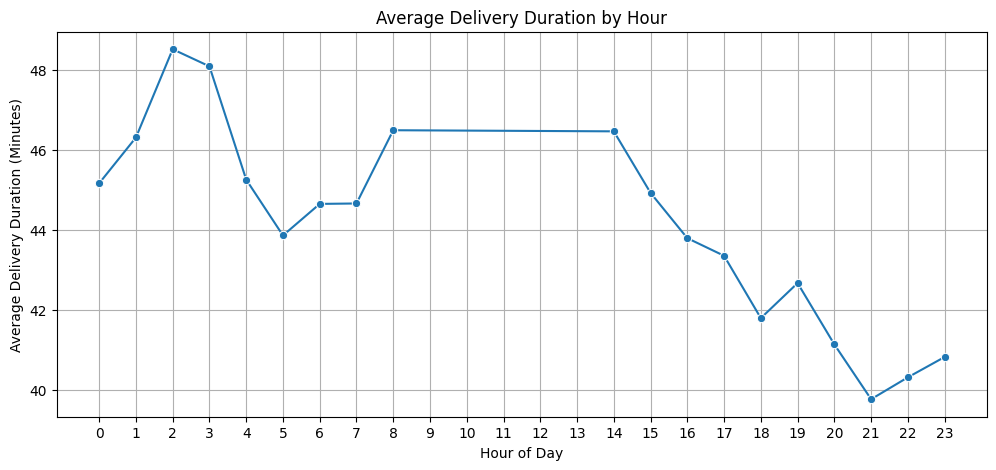

In [132]:
hourly_delivery = df.groupby('order_hour')['actual_delivery_duration'].mean()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_delivery.index,
    y=hourly_delivery.values,
    marker='o'
)

plt.title('Average Delivery Duration by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Delivery Duration (Minutes)')
plt.xticks(range(24))
plt.grid(True)
plt.show()

The line plot shows that average delivery duration varies across different hours of the day. Delivery duration is highest during the early morning hours, particularly around 2 AM and 3 AM, at approximately 48 minutes. It generally decreases during the evening, reaching its lowest value around 9 PM at approximately 40 minutes. This suggests that delivery duration may vary depending on the time of order placement. However, averages for hours with very few records should be interpreted cautiously, and hours with no orders have no available delivery-duration measurements.

**Task 4.1: Split data into training and test sets**

In [133]:
X = df.drop('actual_delivery_duration', axis=1)

y = df['actual_delivery_duration']

In [134]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [135]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (119405, 86)
X_test shape: (29852, 86)
y_train shape: (119405,)
y_test shape: (29852,)


The cleaned and encoded dataset was split into training and testing sets using an 80:20 ratio with random_state=42 to ensure reproducibility. The training set contains 119,405 records, while the testing set contains 29,852 records, with 86 independent features in both sets.

**Task 4.2: Train a random forest regression model as your baseline.**

In [86]:
from sklearn.ensemble import RandomForestRegressor

In [136]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

A baseline Random Forest Regression model was successfully trained using 100 decision trees on the training dataset. The model will be used to predict delivery duration and evaluate its performance on unseen test data.

**Task 4.3: Evaluate the random forest on the test set using multiple error metrics, and identify which features matter most.**

In [137]:
# Generate predictions
y_pred = rf_model.predict(X_test)

# Display first 10 predictions
print("Actual values:", y_test.head(10).values)
print("Predicted values:", y_pred[:10])

Actual values: [36. 49. 44. 46. 60. 40. 54. 36. 49. 46.]
Predicted values: [36.55 51.75 42.42 46.69 56.29 40.23 53.59 35.11 47.67 46.37]


In [138]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1.2247480905801957
MSE: 2.755522624949752
RMSE: 1.6599766940983696
R2 Score: 0.9592310081015638


The baseline Random Forest Regression model achieved an R² score of 0.9592, explaining approximately 95.92% of the variation in actual delivery duration. The model recorded an MAE of 1.2247 minutes and an RMSE of 1.6600 minutes, indicating that its predictions are relatively close to the actual delivery durations. Overall, the model demonstrates strong predictive performance on the test dataset.

In [140]:
# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
print(feature_importance.head(15))

                                         Feature  Importance
10  estimated_store_to_consumer_driving_duration    0.255587
9                       total_outstanding_orders    0.247414
7                          total_onshift_dashers    0.177556
11                                    order_hour    0.080673
3                                       subtotal    0.080001
0                                      market_id    0.071980
12                                     order_day    0.027626
1                                 order_protocol    0.020593
8                             total_busy_dashers    0.017726
6                                 max_item_price    0.005526
5                                 min_item_price    0.004551
4                             num_distinct_items    0.002866
2                                    total_items    0.001948
47                      store_primary_category_4    0.000530
54                     store_primary_category_46    0.000447


The feature importance analysis shows that estimated store-to-consumer driving duration (25.56%), total outstanding orders (24.74%), and total on-shift dashers (17.76%) are the three most influential features in predicting delivery duration. Together, they account for approximately 68.06% of the total feature importance. This suggests that travel distance and delivery operations, such as order workload and dasher availability, play important roles in predicting delivery time. Item-related features have relatively lower importance in the model.

Other classical machine learning algorithms suitable for this regression problem include:
1. Linear Regression – Predicts a continuous target using a linear relationship between input features and the target.
2. K-Nearest Neighbors (KNN) Regression – Predicts delivery duration based on the average target values of nearby data points.
3. Decision Tree Regression – Uses decision rules to predict continuous values.
4. Gradient Boosting Regression – Builds multiple trees sequentially, with each tree attempting to correct previous errors.
5. Support Vector Regression (SVR) – Uses support vector techniques to predict continuous values.

**Task 5.1: Scale the feature data before feeding it into a neural network, and explain why scaling matters here but wasn't required for the random forest.**

Feature scaling is important for Neural Networks because the input features have different ranges and magnitudes. For example, `subtotal` may have values in the thousands, while `order_hour` ranges from 0 to 23 and one-hot encoded features contain only 0s and 1s. Since Neural Networks use gradient descent for learning, differences in feature scales can affect weight updates and make training slower or less stable. Scaling brings the features to a comparable range, helping the model learn more efficiently.

Random Forest, on the other hand, is a tree-based algorithm that makes decisions using feature thresholds. Since it relies on splitting data based on feature values rather than gradient-based weight updates, it is generally not sensitive to differences in feature scales and does not require feature scaling.

In [141]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (119405, 86)
Testing data shape: (29852, 86)


The training and testing feature datasets were successfully standardized using StandardScaler. The training dataset contains 119,405 records with 86 features, while the testing dataset contains 29,852 records with the same 86 features. The same scaling parameters fitted on the training data were applied to the testing data to prevent data leakage.

**Task 5.2 – PyTorch implementation**

In [142]:
import torch
import torch.nn as nn

class DeliveryDurationNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(86, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
model = DeliveryDurationNN()

print(model)

DeliveryDurationNN(
  (network): Sequential(
    (0): Linear(in_features=86, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


**Task 5.3: Compile the model with an optimizer and loss function suited to this regression task, and briefly justify your choice of optimizer.**

In [143]:
import torch.optim as optim

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


The Mean Squared Error (MSE) loss function was selected to measure the difference between actual and predicted delivery durations. It calculates the average of the squared prediction errors, penalizing larger errors more significantly. The Adam optimizer was chosen to update the network weights and minimize the loss during training. A learning rate of 0.001 was configured to control the size of weight updates. Adam is an adaptive optimization algorithm that adjusts learning rates for individual parameters, helping the neural network learn efficiently.

**Task 5.4: Train the network for a reasonable number of epochs, then plot training vs validation loss to check for overfitting**

Step 1: Prepare training and validation data
We already have a separate test dataset. We should not use it during training or validation.

Let's split the existing training data into:
- 80% training data
- 20% validation data

In [144]:
from sklearn.model_selection import train_test_split

X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=42
)

**Step 2: Convert data into PyTorch tensors**
**PyTorch models work with tensors, so we need to convert our NumPy arrays and Pandas Series.**

In [145]:
import torch

X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_nn, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train_nn.values.reshape(-1, 1),
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val_nn.values.reshape(-1, 1),
    dtype=torch.float32
)

**Step 3: Create DataLoaders**
**Batches of 256 records rather than feeding the entire dataset at once.**

In [146]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(
    train_dataset, batch_size=256, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=256, shuffle=False
)

**Step 4: Train the neural network**
**We will track the training and validation losses for every epoch.**

In [147]:
epochs = 50

train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training phase
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)

    # Validation phase
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Training Loss: {epoch_train_loss:.6f}, "
        f"Validation Loss: {epoch_val_loss:.6f}"
    )

Epoch [1/50], Training Loss: 527.547483, Validation Loss: 27.037676
Epoch [2/50], Training Loss: 18.136992, Validation Loss: 11.739957
Epoch [3/50], Training Loss: 9.009238, Validation Loss: 7.394201
Epoch [4/50], Training Loss: 6.670267, Validation Loss: 6.174235
Epoch [5/50], Training Loss: 5.785171, Validation Loss: 5.415236
Epoch [6/50], Training Loss: 5.110494, Validation Loss: 4.817252
Epoch [7/50], Training Loss: 4.537535, Validation Loss: 4.217585
Epoch [8/50], Training Loss: 4.019786, Validation Loss: 3.807424
Epoch [9/50], Training Loss: 3.542835, Validation Loss: 3.295370
Epoch [10/50], Training Loss: 3.130838, Validation Loss: 2.989156
Epoch [11/50], Training Loss: 2.774941, Validation Loss: 2.684414
Epoch [12/50], Training Loss: 2.478776, Validation Loss: 2.564446
Epoch [13/50], Training Loss: 2.248279, Validation Loss: 2.189185
Epoch [14/50], Training Loss: 2.006322, Validation Loss: 1.964053
Epoch [15/50], Training Loss: 1.750574, Validation Loss: 1.842385
Epoch [16/50],

**Step 5: Plot training vs validation loss**

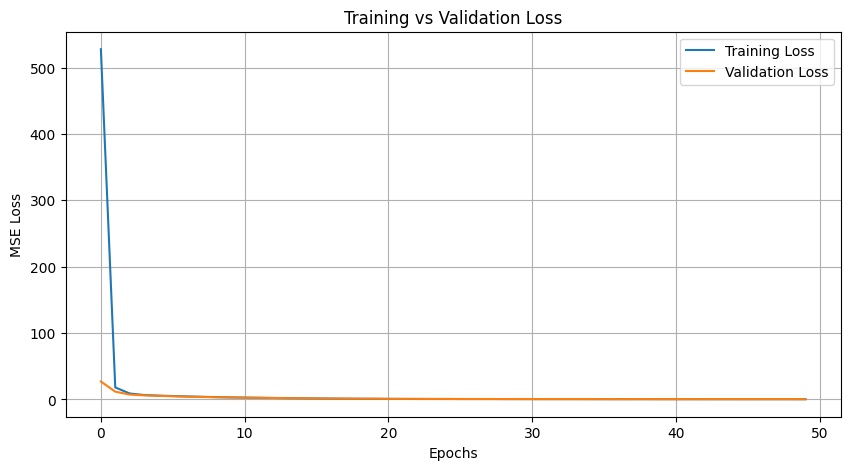

In [148]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Training vs Validation Loss')

plt.legend()
plt.grid(True)
plt.show()

The training and validation loss curves show that the neural network learns effectively, with both losses decreasing significantly during the initial epochs. The losses gradually converge towards very low values and remain stable during the later epochs. There is no clear indication of overfitting, as the validation loss does not increase while the training loss continues to decrease. Overall, the learning curves indicate that the model has converged and learned the underlying patterns in the training data.

**Task 5.5: Evaluate the trained network on the test set using the same set of metrics used for the random forest, and directly compare the two models' results.**

**Step 1: Prepare the test data as PyTorch tensors**
We already scaled X_test using the StandardScaler fitted on the training data

In [149]:
import torch

X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.values.reshape(-1, 1),
    dtype=torch.float32
)

**Step 2: Generate predictions**
Put the model in evaluation mode and disable gradient calculations.

In [150]:
model.eval()

with torch.no_grad():
    y_pred_nn = model(X_test_tensor)

# Convert predictions into NumPy array
y_pred_nn = y_pred_nn.numpy().flatten()

**Step 3: Calculate evaluation metrics**

In [151]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae_nn = mean_absolute_error(y_test, y_pred_nn)

mse_nn = mean_squared_error(y_test, y_pred_nn)

rmse_nn = np.sqrt(mse_nn)

r2_nn = r2_score(y_test, y_pred_nn)

print("Neural Network Performance")
print("MAE:", mae_nn)
print("MSE:", mse_nn)
print("RMSE:", rmse_nn)
print("R2 Score:", r2_nn)

Neural Network Performance
MAE: 0.4118197146040911
MSE: 0.3402884340333927
RMSE: 0.5833424671952083
R2 Score: 0.9949653048446692


In [152]:
comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Random Forest': [mae, mse, rmse, r2],
    'Neural Network': [mae_nn, mse_nn, rmse_nn, r2_nn]
})

print(comparison)

     Metric  Random Forest  Neural Network
0       MAE       1.224748        0.411820
1       MSE       2.755523        0.340288
2      RMSE       1.659977        0.583342
3  R2 Score       0.959231        0.994965


The Neural Network regression model achieved excellent performance on the test dataset, with an R² score of 0.9950, indicating that it explains approximately 99.50% of the variation in actual delivery duration. The model recorded an MAE of 0.4118 minutes and an RMSE of 0.5833 minutes, demonstrating that its predictions are close to the actual delivery times. Compared with the Random Forest model, the Neural Network achieved lower MAE, MSE and RMSE values and a higher R² score. Therefore, the Neural Network demonstrated better predictive performance on this dataset.

**Task 5.6: Explain why neural networks tend to perform well as dataset size grows.**

Neural Networks tend to perform well as dataset size increases because they can learn complex patterns, non-linear relationships, and interactions between multiple features. A larger and more diverse dataset provides more examples for the network to learn from, helping it improve its ability to generalize to unseen data. It can also reduce overfitting by preventing the model from relying too heavily on a limited number of training observations. However, the benefits depend on data quality, model architecture, and appropriate training.

In [153]:
print("Target in X_train:",
      'actual_delivery_duration' in X_train.columns)

print("Target in X_test:",
      'actual_delivery_duration' in X_test.columns)

print("Actual delivery timestamp in X_train:",
      'actual_delivery_time' in X_train.columns)

print("Actual delivery timestamp in X_test:",
      'actual_delivery_time' in X_test.columns)

Target in X_train: False
Target in X_test: False
Actual delivery timestamp in X_train: False
Actual delivery timestamp in X_test: False
